This notebook reproduces results from Section V: Polygonal Faces of the paper
"Phase locking and multistability in the topological Kuramoto model on cell complexes".

It generates Figures 3–5, demonstrating phase-locked states and multistability patterns in ring cell complexes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

from core.complexes import compute_boundary_matrices, get_C_from_B, get_K_from_B

from core.dynamics import find_all_plus_omega_zero_solutions, all_partitions

from core.rings import (
    find_what_works_ring,
    plot_ring_fcurves_grouped_stable,
    plot_all_phase_locked_solutions_for_varying_w0_both,
    plot_bifurcation_ring_branches,
    theta_star_from_ring_root, simulate_theta,
    make_figure_3,
    make_figure_4,
    plot_figure_5
)


Let us start by defining a ring with 6 nodes and 6 edges, finding relevant matrices and defining all possible partitions of the ring.

In [2]:
S0_ring = [[1], [2], [3], [4], [5], [6]]
S1_ring = [[1,2], [2,3], [3,4], [4,5], [5,6], [6,1]]
S2_ring = [[1,2,3,4,5,6]]

S_ring = [S0_ring, S1_ring, S2_ring]
boundary_matrices_ring = compute_boundary_matrices(S_ring)

B1r, B2r = boundary_matrices_ring
C1r, C2r = get_C_from_B(B1r, B2r)
K1r, K2r = get_K_from_B(B1r, B2r)

ring_partitions = all_partitions(len(S_ring[1]))

Test the solution finder for any of 64 partitions -- this one looks for all solutions, not only stable ones!

In [3]:
S_plus, S_minus = ring_partitions[0] # index determines which partition to use, zero-th is the all-normal partition

roots_ring = find_what_works_ring(S_plus=S_plus, S_minus=S_minus, B1=B1r, K1=K1r, C1=C1r, z_range=range(-1, 5), verbose=False)

print(roots_ring)

[(array([], dtype=float64), array([2]), array([], dtype=float64), array([0.8660254])), (array([], dtype=float64), array([3]), array([], dtype=float64), array([0.])), (array([], dtype=float64), array([4]), array([], dtype=float64), array([-0.8660254]))]


# Figure 3

Figure 3a is a graphical solution: we plot $C_1^\top f_0 (\psi^{[-]})/(2\pi)$ and check where it intersects integer values. All 64 solutions will be grouped into 7 curves according to multiset permutations which conserve the length of the partitions.

Fig3b shows time series of the three stable solutions that exist for the all-normal partition.

In [4]:
# Simulate dynamics from perturbed fixed points
all_results = []
all_xstars = []

omega = np.zeros(B1r.shape[1])

theta_stars = []
for root in roots_ring:
    z_plus, z_minus, zeta_plus, zeta_minus = root
    theta_star = theta_star_from_ring_root(zeta_minus, S_plus, S_minus, n_edges=6)
    theta_stars.append(theta_star)
    print(theta_star, " winding =", np.sum(theta_star)/(2*np.pi))

sims = []
for i, theta_star in enumerate(theta_stars):
    sol = simulate_theta(theta_star, tmax=20, npts=2500, noise=2e-2, seed=10+i, preserve_sum=True)
    sims.append(sol)

[1.04719755 1.04719755 1.04719755 1.04719755 1.04719755 1.04719755]  winding = 1.0000000000000002
[0. 0. 0. 0. 0. 0.]  winding = 0.0
[-1.04719755 -1.04719755 -1.04719755 -1.04719755 -1.04719755 -1.04719755]  winding = -0.9999999999999999


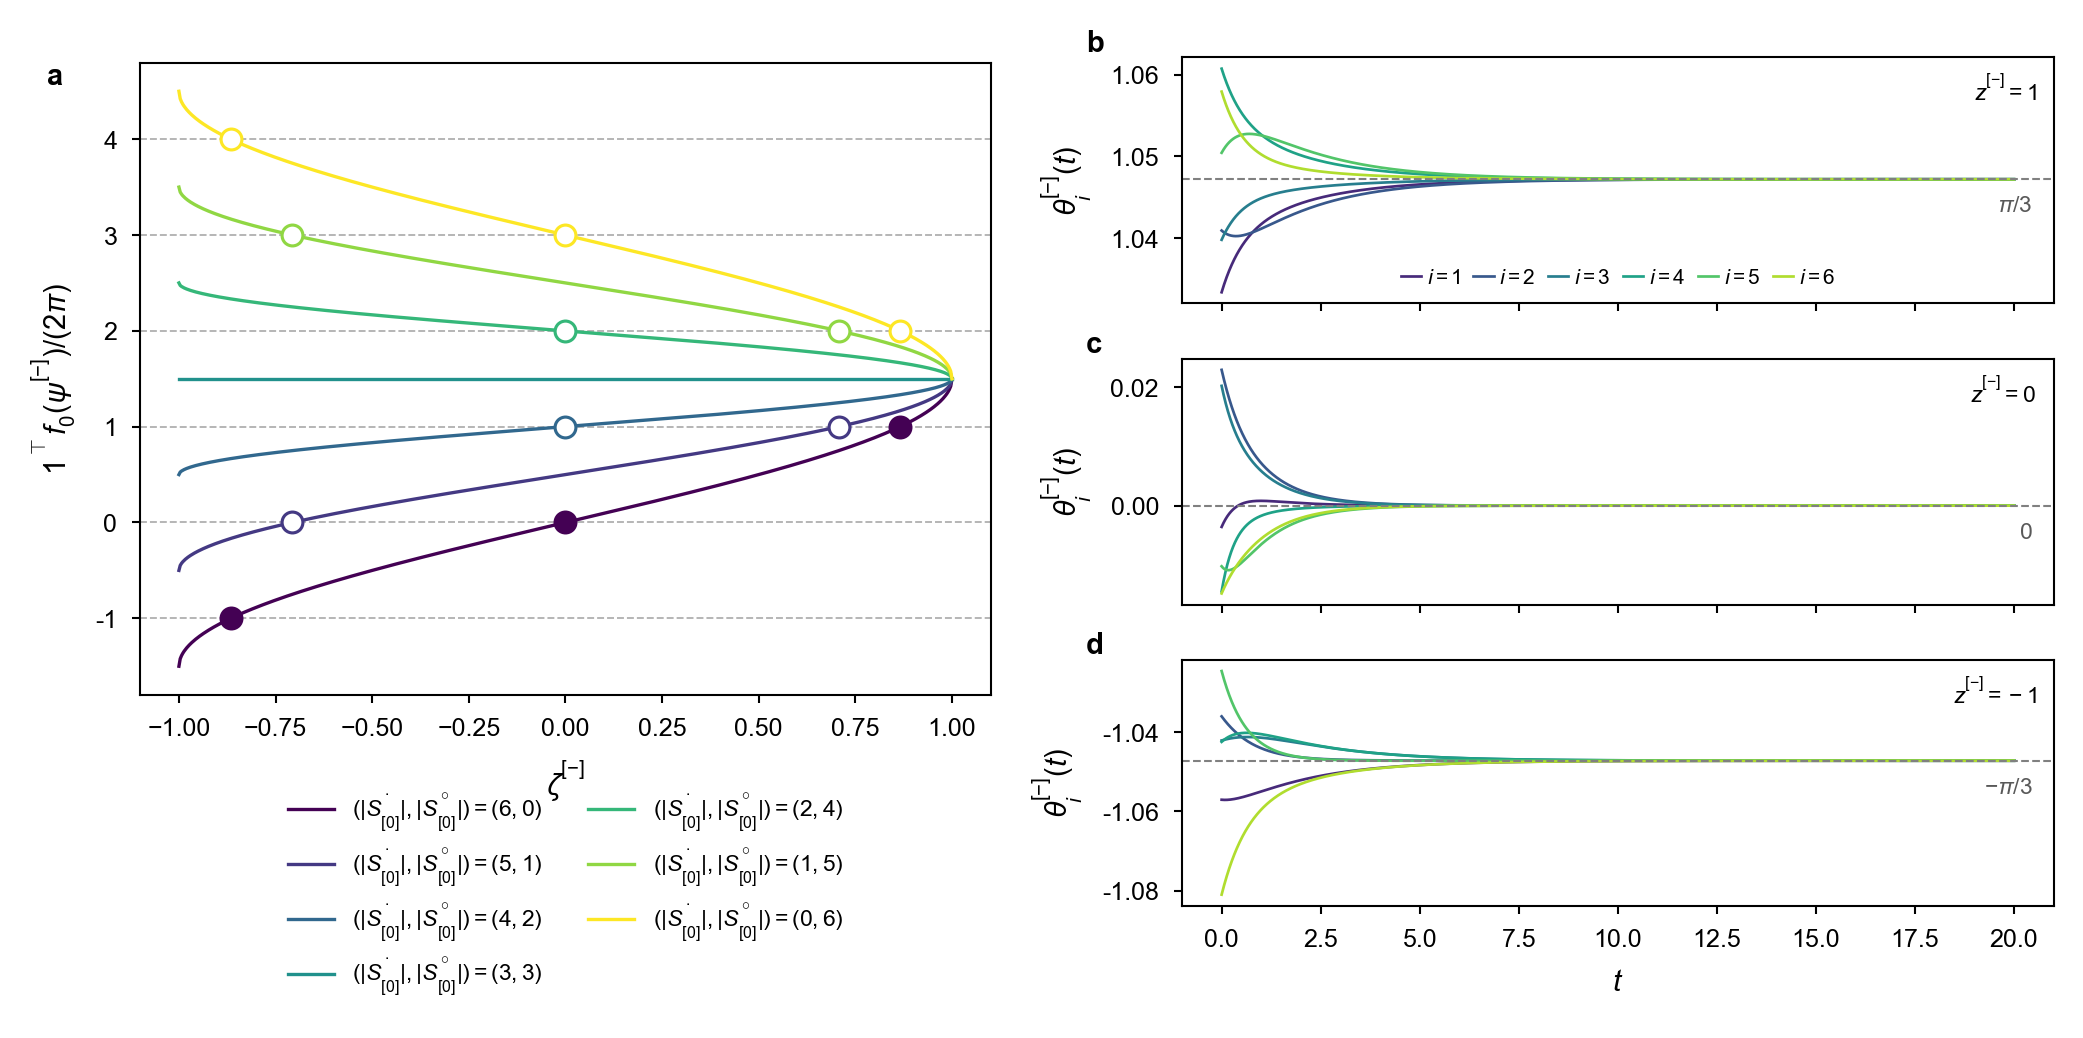

In [5]:
make_figure_3(B1r, K1r, C1r, ring_partitions, sims, theta_stars, omega=None, save_path="Fig3final.pdf")

# Figure 4

In Fig 4a, we study the effect of inhomogeininty in intrinsic frequencies by setting $\vec \omega = (0, 0, 0, 0, +\omega_0, -\omega_0)$. We plot  $C_1^\top f_0(\psi^{[-]})/(2\pi)$ as a function of $\zeta^{[-]}$ for the all-plus partition (solid lines) and the $S_{[0]}^\circ = [5, 6]$ partition (dashed lines).
The inset shows a curious phenomenon: for a narrow interval of $\omega_0$ values, the solution arising from $S_{[0]}^\circ = [5, 6]$ crosses zero twice, with one solution becoming stable, while $S_{[0]}^\circ = \emptyset$ does not intersect zero.

Fig 4b demonstrates that the stable solution $S_{[0]}^\circ = \emptyset$ (orange line) at around $\omega_0 \approx 1.309$ becomes the stable solution $S_{[0]}^\circ = [5, 6]$ when $\theta^{[-]}_5$ crosses $\pi/2$. The stable (solid blue line) and unstable solution (dashed blue line) of $S_{[0]}^\circ = [5, 6]$ vanish in a saddle-node bifurcation around $\omega_0 \approx 1.327$.

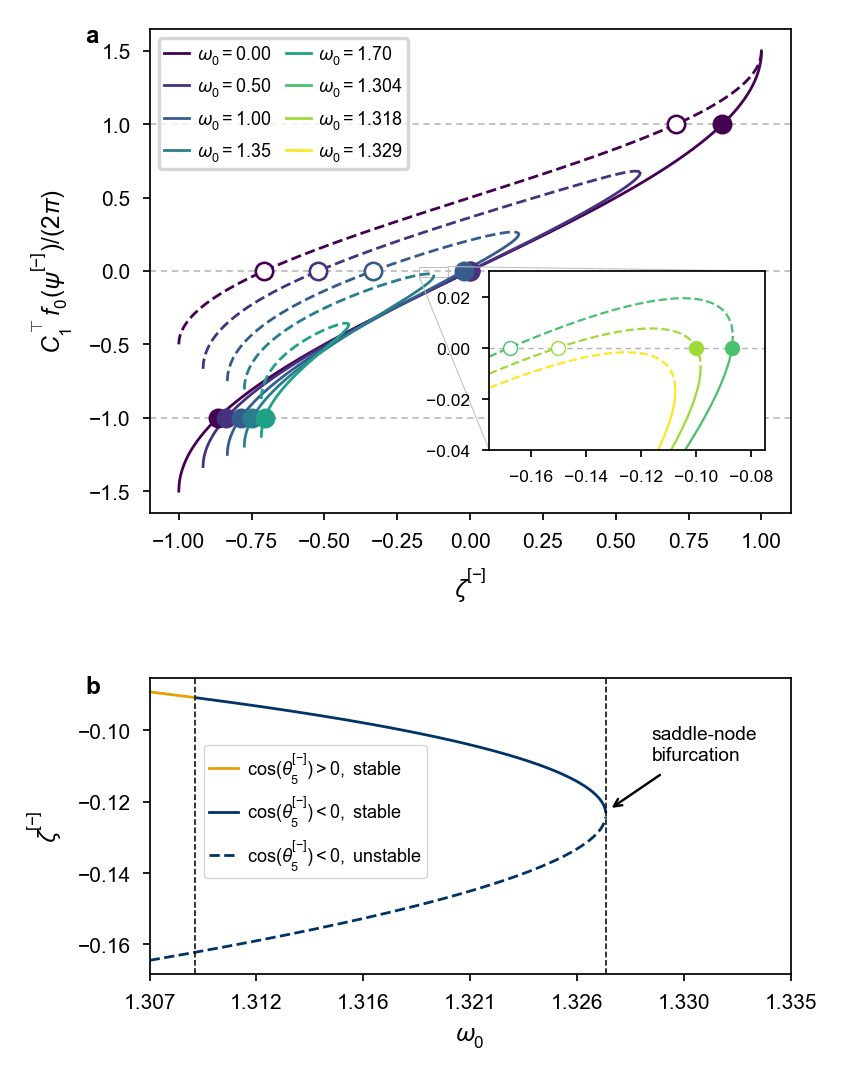

In [4]:
Sp0, Sm0 = ring_partitions[0]
Sp1, Sm1 = ring_partitions[1]

w0_vals_main = [0.0, 0.5, 1.0, 1.35, 1.7]
w0_vals_inset = [1.304, 1.318, 1.329]

omega0_vals = np.unique(np.concatenate([
    np.linspace(1.3070, 1.3260, 200, endpoint=False),
    np.linspace(1.3260, 1.3275, 200, endpoint=False),
    np.linspace(1.3275, 1.3350, 10)
]))

make_figure_4(Sp0, Sm0, Sp1, Sm1, B1r, K1r, C1r, w0_vals_main, w0_vals_inset, omega0_vals, save_path="Fig4final.pdf")

# Figure 5

Finally, we study the number of stable solutions $N_{\rm stable}$ depending on ring size $s$ in an all-normal partitioned ring, comparing numerical results and our theoretical prediction.

In [5]:
# Generate ring complexes
def generate_rings(n):
    """
    Construct a 1D ring (cycle) complex with n vertices.

    Returns:
        S0 : list of [vertex]
        S1 : list of [i, j] edges (cyclic)
        S2 : list containing one [1, 2, ..., n] face
    """
    S0 = [[i] for i in range(1, n + 1)]
    S1 = [[i, (i % n) + 1] for i in range(1, n + 1)]
    S2 = [list(range(1, n + 1))]
    return S0, S1, S2


# Simulation 
all_sols = []
ring_sizes = list(range(3, 33))

for ring_size in ring_sizes:
    print(f"n = {ring_size}")
    S_ring = generate_rings(ring_size)
    sols = find_all_plus_omega_zero_solutions(S_ring, 1, False, tol=1e-7)
    print(f"Total of {len(sols)} solutions.")
    all_sols.append(sols)

# Theory 
sol_num = [len(sols) for sols in all_sols]

def ring_size_function(n):
    return 1 + 2 * math.floor((n - 1) / 4)

ring_sizes_calc = [ring_size_function(n) for n in ring_sizes]

n = 3
n = 1,
C_n = [[1. 1. 1.]],
C_np1 = []
total of 1 different z_n_vecs considered, and 1 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ([], (0,))
zeta_plus = [], zeta_minus = [0.]
Solution z+ = [], z- = (0,): is stable.
Solution z+ = [], z- = (0,): all cos(theta) > 0.
Root 1: z+ = [], z- = (0,), zeta_plus = [], zeta_minus = [0.], Stable: True, Positive: True
Cos(theta)_minus: [1. 1. 1.] 
 Eig J1:[-3.00000000e+00 -3.00000000e+00  1.11022302e-16]
 Cos(theta)_plus: None
 Eig J2:None

Total of 1 solutions.
n = 4
n = 1,
C_n = [[1. 1. 1. 1.]],
C_np1 = []
total of 1 different z_n_vecs considered, and 1 different z_np1_vecs.
Phase-locked solutions:
(z_plus, z_minus) = ([], (0,))
zeta_plus = [], zeta_minus = [0.]
Solution z+ = [], z- = (0,): is stable.
Solution z+ = [], z- = (0,): all cos(theta) > 0.
Root 1: z+ = [], z- = (0,), zeta_plus = [], zeta_minus = [0.], Stable: True, Positive: True
Cos(theta)_minus: [1. 1. 1. 1.] 
 Eig J1:[-4.00000000e+00 -2.00000000e+00 -2.00000

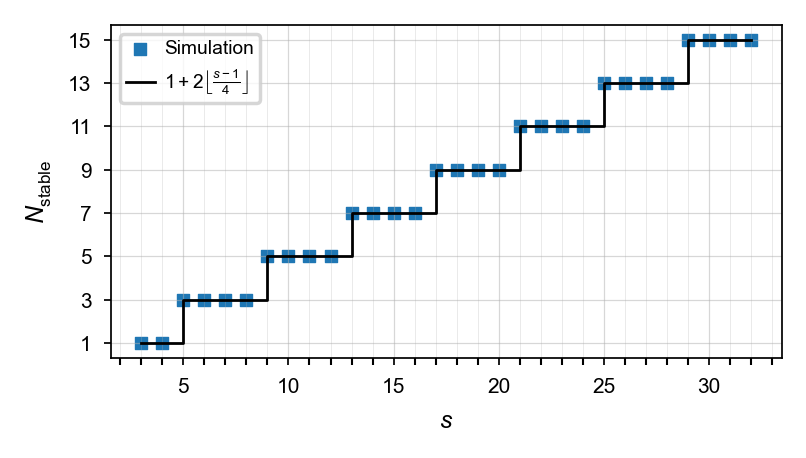

In [7]:
plot_figure_5(ring_sizes, sol_num, ring_sizes_calc, save_path="Fig5final.pdf")